## Library import


In [69]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
from scipy.stats import ttest_ind
from scipy import stats
from sklearn.preprocessing import StandardScaler

## Data Import

In [ ]:
players = pd.read_csv('..//data/cleaned/players_clean.csv')
exprience = pd.read_csv('..//data/cleaned/exprience_clean.csv')
mvp_votes = pd.read_csv('..//data/cleaned/mvp_votes_clean.csv')
player_season = pd.read_csv('..//data/cleaned/player_season_clean.csv')
positons = pd.read_csv('..//data/cleaned/positons_clean.csv')
seasons = pd.read_csv('..//data/cleaned/seasons_clean.csv')
teams = pd.read_csv('..//data/cleaned/team_clean.csv')
champions = pd.read_csv('..//data/processed/champions.csv')

## Used function

### Player Performance Scoring Method

To identify the top-performing players, we created a composite score based on three statistical metrics: **Value Over Replacement Player (VORP), Box Plus/Minus (BPM), and Win Shares (WS)**.

First, we standardized these metrics using `StandardScaler` to put them on a comparable scale. Then, we calculated a weighted score for each player:

- **VORP (50%)**: Measures a player's contribution compared to a replacement-level player.
- **BPM (30%)**: Estimates a player's overall impact on the team per 100 possessions.
- **WS (20%)**: Estimates a player's contribution to team wins.

The final score is calculated as:

**Score = 0.5 × VORP_z + 0.3 × BPM_z + 0.2 × WS_z**

VORP receives the highest weight because it is the primary metric in this scoring model. Players are then ranked by their final scores, with higher scores indicating stronger overall performance according to the selected metrics and weights.

**Note:** This is a custom scoring model designed for this analysis, not an official NBA ranking formula.

In [5]:
def calculate_score(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    scaler = StandardScaler()
    df[["vorp_z", "bpm_z", "ws_z"]] = scaler.fit_transform(df[["vorp", "bpm", "ws"]])
    df["score"] = 0.5 * df["vorp_z"] + 0.3 * df["bpm_z"] + 0.2 * df["ws_z"]
    return df


def attach_experience(data: pd.DataFrame, experience: pd.DataFrame) -> pd.DataFrame:
    by_season = experience[
        ["player_id", "season", "experience_years"]
    ].drop_duplicates()
    return data.merge(
        by_season,
        on=["player_id", "season"],
        how="left",
        validate="many_to_one",
    )


## Data Preparation

In [6]:
# Adding team, season, and position information to the player_season dataframe based on their respective IDs. 
player_season_merged = player_season.copy()

player_season_merged = player_season_merged.merge(
    teams,
    on="team_id",
    how="left"
)

player_season_merged = player_season_merged.merge(
    seasons,
    on="season_id",
    how="left"
)

player_season_merged = player_season_merged.merge(
    positons,
    on="position_id",
    how="left"
)



# Adding season information to the mvp_votes dataframe based on their respective IDs.
mvp_votes_merged = mvp_votes.copy()

mvp_votes_merged = mvp_votes_merged.merge(
    seasons,
    on="season_id",
    how="left"
)



# Adding season and team information to the exprience dataframe based on their respective IDs.
exprience_merged = exprience.copy()

exprience_merged = exprience_merged.merge(
    seasons,
    on="season_id",
    how="left"
)

exprience_merged = exprience_merged.merge(
    teams,
    on="team_id",
    how="left"
)


# Renaming the "team_id" column in the champions dataframe to "team_label" for consistency with other dataframes.
champions = champions.rename(columns={"team_id": "team_label"})


## Descriptive statistics

### Height Distribution

In [7]:
# Selecting records from 2020 to 2024
playerdf = player_season_merged[
    player_season_merged['season'].between(2020, 2024)
].copy()

# Selecting required columns
playerdf = playerdf[['player_id', 'season', 'is_total', 'vorp', 'bpm', 'ws']]

# Selecting the records of interest
playerdf = playerdf[playerdf['is_total'] == 1]

playerdf = calculate_score(playerdf)

playerdf.drop_duplicates()
# Selecting the top 50 players based on the score
top_50 = playerdf.nlargest(50, 'score')


In [8]:
# Merging the top 50 players with their height information from the players dataframe.

top_50_hights = top_50.merge(
    players[['player_id', 'height_cm']],
    on='player_id',
    how='left'
)

top_50_hights = top_50_hights[['player_id', 'height_cm']]

In [9]:
# Merging the mvp votes with their height information from the players dataframe.

mvp_heights = mvp_votes_merged.merge(
    players[['player_id', 'height_cm']],
    on='player_id',
    how='left'
)


mvp_heights = mvp_heights[['player_id', 'height_cm']].drop_duplicates()

### Plots

#### Height Distribution

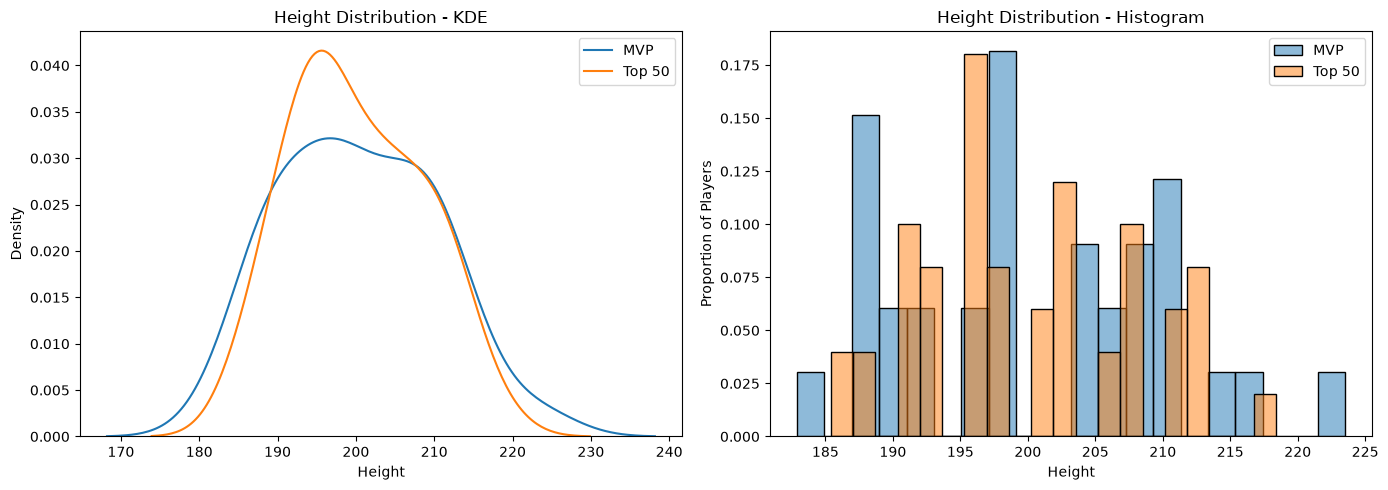

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# KDE Plot
sns.kdeplot(data=mvp_heights, x='height_cm', label='MVP', ax=axes[0])
sns.kdeplot(data=top_50_hights, x='height_cm', label='Top 50', ax=axes[0])

axes[0].set_title('Height Distribution - KDE')
axes[0].set_xlabel('Height')
axes[0].set_ylabel('Density')
axes[0].legend()

# Histogram
sns.histplot(
    data=mvp_heights, x='height_cm', bins=20,
    stat='probability', alpha=0.5, label='MVP', ax=axes[1]
)
sns.histplot(
    data=top_50_hights, x='height_cm', bins=20,
    stat='probability', alpha=0.5, label='Top 50', ax=axes[1]
)

axes[1].set_title('Height Distribution - Histogram')
axes[1].set_xlabel('Height')
axes[1].set_ylabel('Proportion of Players')
axes[1].legend()

plt.tight_layout()
plt.show()

### Experience Distribution

In [11]:
# Seasons to analyze 
recent_seasons = [2025, 2026]

# Selecting records from the recent seasons and ensuring that players have played at least one game.
recent_data = player_season_merged[
    (player_season_merged['season'].isin(recent_seasons)) &
    (player_season_merged['games'] > 0)
].copy()


# Calculating the score for the recent data based on the defined scoring function.
recent_data = calculate_score(recent_data)

# Merging the recent data with the experience information based on player_id and season.
recent_data = attach_experience(recent_data, exprience_merged)

# Merging the recent data with the players height based on player_id.
recent_data = recent_data.merge(
    players[['player_id', 'height_cm']],
    on='player_id',
    how='left'
)

# Selecting the top 15 records for each season based on score.
top_15 = (
    recent_data
    .sort_values('score', ascending=False)
    .groupby('season')
    .head(15)
)

# Sorting the top 15 records by season in descending order for better visualization and analysis.
top_15 = top_15.sort_values('season', ascending=False)

In [12]:
# Seasons to analyze
recent_seasons = [2025, 2026]  

# Selecting records from the recent seasons and ensuring that players have played at least one game.
champion_players =  player_season_merged.copy()


champion_players = champion_players[
    (champion_players['season'].isin(recent_seasons)) &
    (champion_players['games'] > 0)
].copy()

# Merging the recent players with the champions dataframe to get the champion players for the recent seasons.
champion_players = champion_players.merge(
    champions[['season', 'team_label']].drop_duplicates(),
    on=['season', 'team_label'],
    how='inner'
)

champion_players = attach_experience(champion_players, exprience_merged)

# Merging the champion players with the players height based on player_id.
champion_players = champion_players.merge(
    players[['player_id', 'height_cm']].drop_duplicates('player_id'),
    on='player_id',
    how='left'
)

# Sorting the champion players by season in descending order for better visualization and analysis.
champion_players = champion_players.sort_values('season', ascending=False)

In [13]:
# New dataframe for comparison of champion players and top 15 players based on height and experience.
champion_comparison = champion_players[
    ['player_id', 'season', 'height_cm', 'experience_years']
].copy()

top_15_comparison = top_15[
    ['player_id', 'season', 'height_cm', 'experience_years']
].copy()

### Plots

#### High distribution

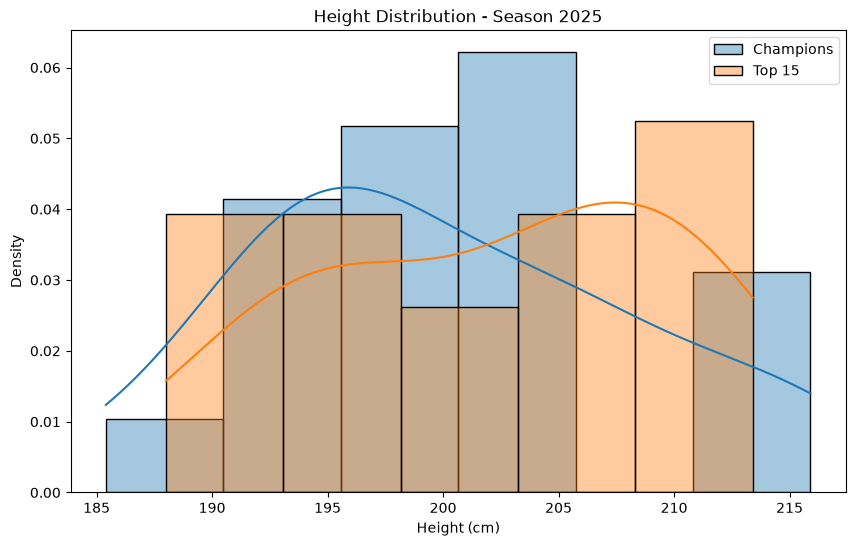

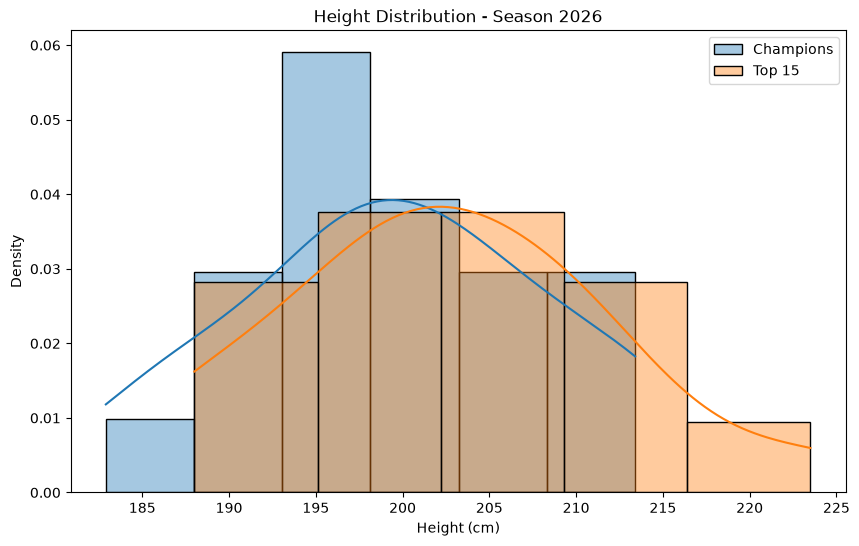

In [14]:
# visualization the height distribution of champion players and top 15 players for each season using histograms and KDE plots.
for season in recent_seasons:

    champions_year = champion_players[
        champion_players['season'] == season
    ]

    top_15_year = top_15[
        top_15['season'] == season
    ]

    plt.figure(figsize=(10, 6))

    sns.histplot(
        data=champions_year,
        x='height_cm',
        stat='density',
        kde=True,
        label='Champions',
        alpha=0.4
    )

    sns.histplot(
        data=top_15_year,
        x='height_cm',
        stat='density',
        kde=True,
        label='Top 15',
        alpha=0.4
    )

    plt.title(f'Height Distribution - Season {season}')
    plt.xlabel('Height (cm)')
    plt.ylabel('Density')
    plt.legend()
    plt.show()

#### Experience Distribution

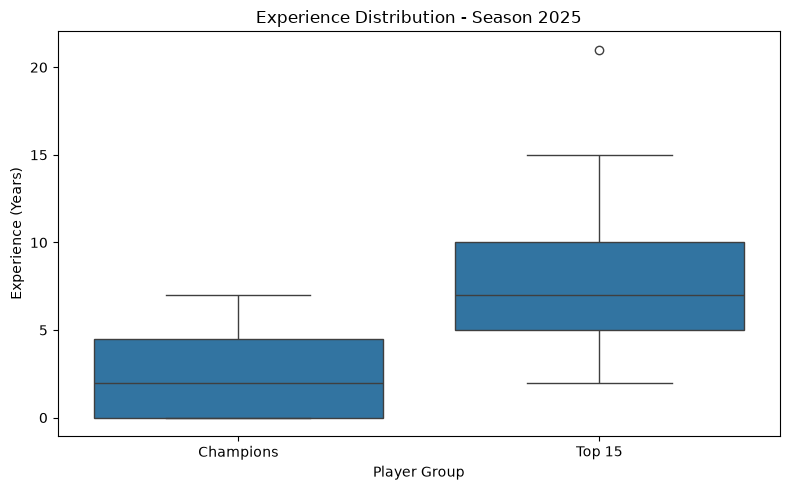

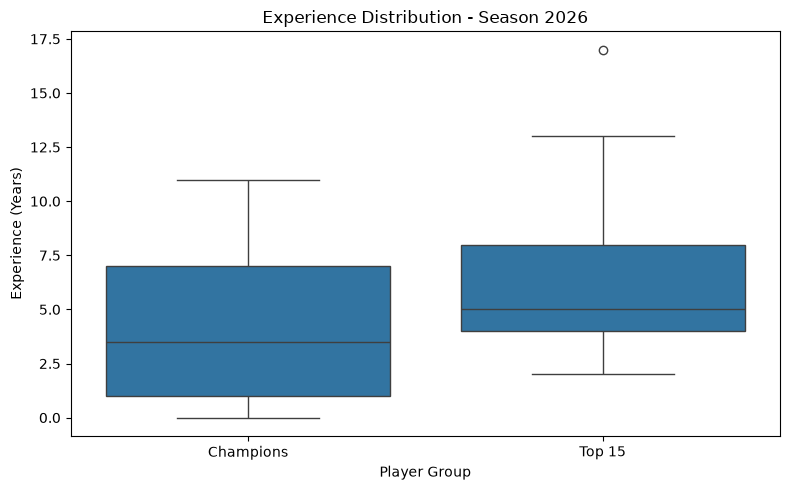

In [15]:
# visualization the experience distribution of champion players and top 15 players for each season using boxplots.
for season in recent_seasons:

    champions_year = champion_players[
        champion_players['season'] == season
    ]

    top_15_year = top_15[
        top_15['season'] == season
    ]

    plot_data = pd.concat([
        champions_year.assign(group='Champions'),
        top_15_year.assign(group='Top 15')
    ])

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=plot_data,
        x='group',
        y='experience_years'
    )

    plt.title(f'Experience Distribution - Season {season}')
    plt.xlabel('Player Group')
    plt.ylabel('Experience (Years)')
    plt.tight_layout()
    plt.show()

#### Height vs Experience

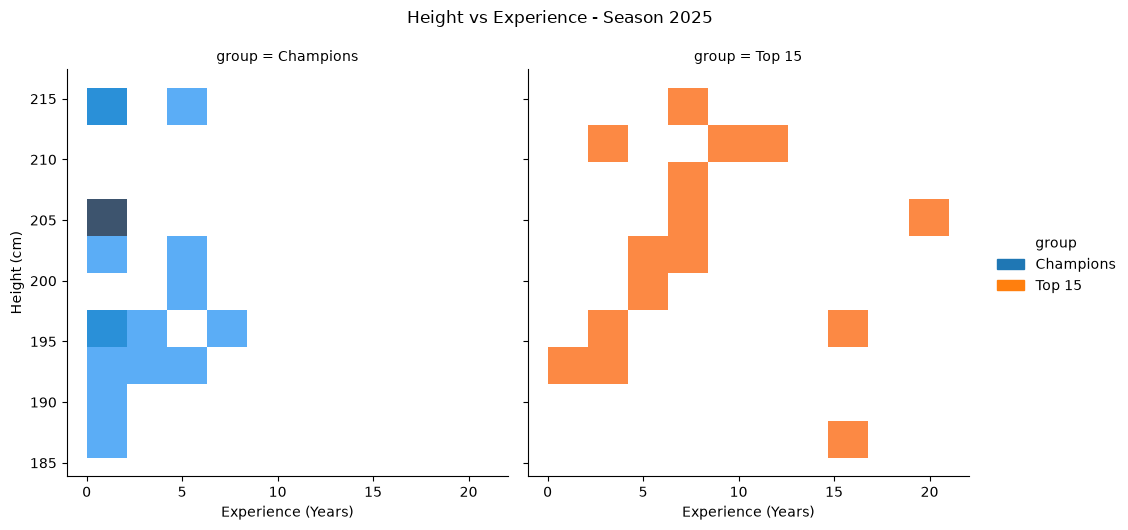

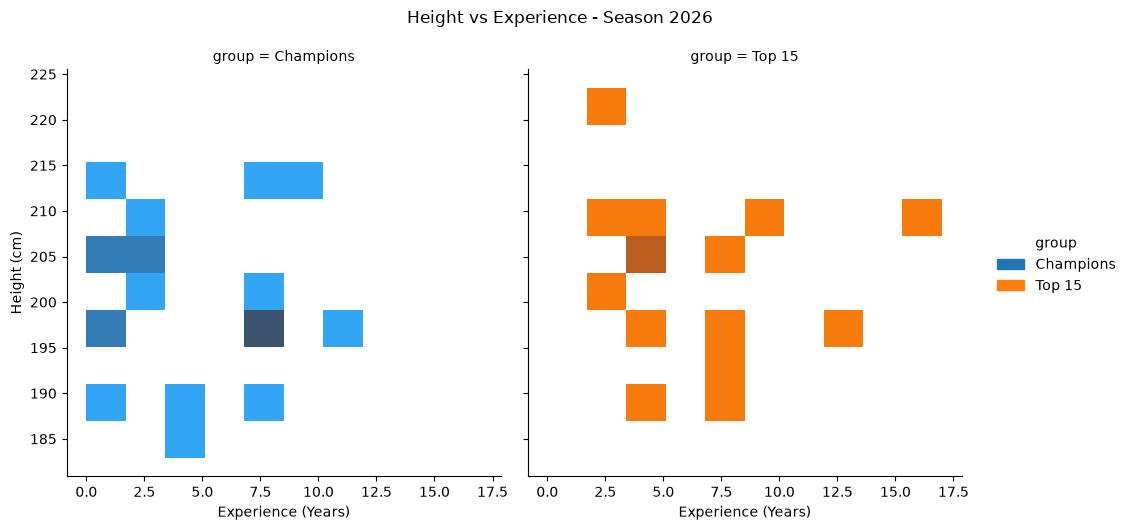

In [16]:
# visualization the experience vs height of champion players and top 15 players for each season using boxplots.
for season in recent_seasons:

    champions_year = champion_players[
        champion_players['season'] == season
    ]

    top_15_year = top_15[
        top_15['season'] == season
    ]

    plot_data = pd.concat([
        champions_year.assign(group='Champions'),
        top_15_year.assign(group='Top 15')
    ])

    g = sns.displot(
        data=plot_data,
        x='experience_years',
        y='height_cm',
        hue='group',
        kind='hist',
        col='group',
        bins=10,
        height=5
    )

    g.set_axis_labels('Experience (Years)', 'Height (cm)')
    g.fig.suptitle(f'Height vs Experience - Season {season}', y=1.05)

    plt.show()

## Investment Option

In [17]:
# Count MVP appearances for each player in the seasons between 2020 and 2024, and sort them in descending order of appearances.
mvp_counts = (
    mvp_votes_merged[
        mvp_votes_merged['season'].between(2020, 2024)
    ]
    .groupby('player_id')
    .size()
    .reset_index(name='appearances')
    .sort_values('appearances', ascending=False)
)

In [18]:
# Merging the MVP counts with the player_season_merged dataframe to get the position of each player.
mvp_counts = mvp_counts.merge(
    player_season_merged[['player_id', 'position']],
    on='player_id',
    how='left'
)

In [19]:
# Selecting only the point guards (PG) from the MVP counts and dropping duplicate entries to ensure each player is represented only once.
pg_players = mvp_counts[
    mvp_counts['position'] == 'PG'
].copy().drop_duplicates()

top_3_pg = pg_players.head(3)

top_3_pg = top_3_pg.merge(
    players[['player_id', 'name']].drop_duplicates('player_id'),
    on='player_id',
    how='left'
)

top_3_pg = top_3_pg[
    ['name', 'position', 'appearances']
]


### Top 3 PG

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_3200\2355122792.py:12: UserWarning: Glyph 141 (\x8d) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_3200\2355122792.py:12: UserWarning: Glyph 135 (\x87) missing from font(s) DejaVu Sans.
  plt.tight_layout()
c:\Users\Lenovo\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 141 (\x8d) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\Lenovo\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 135 (\x87) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


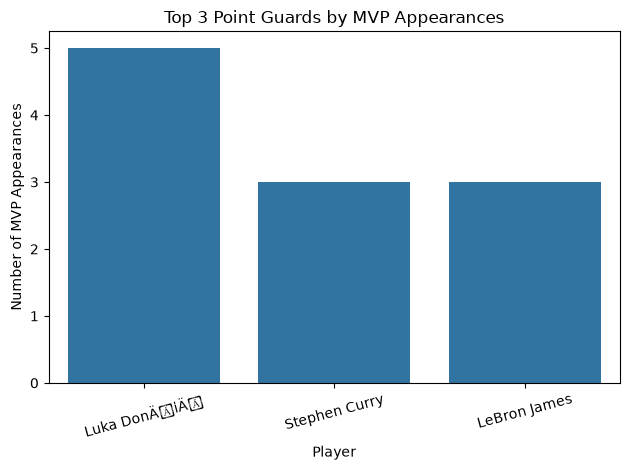

            name position  appearances
0  Luka DonÄiÄ       PG            5
1  Stephen Curry       PG            3
2   LeBron James       PG            3


In [20]:
# Visualizing the top 3 point guards by MVP appearances.
sns.barplot(
    data=top_3_pg,
    x='name',
    y='appearances'
)

plt.title('Top 3 Point Guards by MVP Appearances')
plt.xlabel('Player')
plt.ylabel('Number of MVP Appearances')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print(top_3_pg)

# Agility
### Checking first 20 players in terms of best agility in the leauge between top players in 2022-2023 and 2023-2024 with 2024-2025 and 2025-2026 .

### We first set a meaning of agility from below formula, As you can see the from height proportion to the weight we can find the agility.
##### Agility = Height / Weight

In [35]:
def Agility(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df['Agility'] = df['height_cm'] / df['weight_kg']
    return df

In [36]:
df_scored = calculate_score(player_season)
top_20 = (
    df_scored
    .sort_values(["season_id", "score"], ascending= False)
    .groupby("season_id")
    .head(20)
    .reset_index(drop=True)
)
top_20 = top_20 [['season_id','player_id','score']]
players_HW= players[['player_id','height_cm','weight_kg']]
top_20_target= top_20.merge(players_HW,how='left',on='player_id')
top_20_target

,season_id,player_id,score,height_cm,weight_kg
0,7,jokicni01,6.226588,210.8,128.8
1,7,gilgesh01,5.442262,198.1,88.4
2,7,doncilu01,4.241022,203.2,104.3
3,7,wembavi01,4.088064,223.5,106.6
4,7,leonaka01,3.525355,198.1,102.1
...,...,...,...,...,...
135,1,vucevni01,2.018861,205.7,120.2
136,1,sabondo01,1.958567,208.3,108.9
137,1,youngtr01,1.957433,188.0,74.4
138,1,lowryky01,1.911621,182.9,88.9


In [41]:
top_20_agility=Agility(top_20_target)
top_20_agility = top_20_agility[['season_id','player_id','score','Agility']]
top_20_agility

,season_id,player_id,score,Agility
0,7,jokicni01,6.226588,1.636646
1,7,gilgesh01,5.442262,2.240950
2,7,doncilu01,4.241022,1.948226
3,7,wembavi01,4.088064,2.096623
4,7,leonaka01,3.525355,1.940255
...,...,...,...,...
135,1,vucevni01,2.018861,1.711314
136,1,sabondo01,1.958567,1.912764
137,1,youngtr01,1.957433,2.526882
138,1,lowryky01,1.911621,2.057368


In [56]:
agility22 = top_20_agility[top_20_agility['season_id'] < 3]
agility24 = top_20_agility[(top_20_agility['season_id'] == 3) | (top_20_agility['season_id'] == 4)]

In [52]:
season_agility22 = agility22.set_index("season_id")
season_agility22

,player_id,score,Agility
season_id,,,
2,jokicni01,5.970651,1.636646
2,antetgi01,3.813519,1.858907
2,curryst01,3.785674,2.072767
2,lillada01,3.383910,2.072767
2,doncilu01,3.228827,1.948226
2,butleji01,3.046160,1.899329
2,leonaka01,2.931668,1.940255
2,goberru01,2.812456,1.845299
2,embiijo01,2.756119,1.742041


In [57]:
season_agility24 = agility24.set_index("season_id")
season_agility24

,player_id,score,Agility
season_id,,,
4,jokicni01,5.965398,1.636646
4,embiijo01,4.382243,1.742041
4,doncilu01,4.276861,1.948226
4,butleji01,4.069982,1.899329
4,gilgesh01,3.812911,2.240950
4,sabondo01,3.730646,1.912764
4,antetgi01,3.551195,1.858907
4,tatumja01,3.390534,2.134454
4,lillada01,3.265286,2.072767


# Ttest for agility
##### H0 = mio 2 <= mio1 therefore there is no significant difference
##### H1 = mio 1 < mio2 therefore there is significant difference

In [64]:

result = ttest_ind(
    season_agility24['Agility'],
    season_agility22['Agility'],
    alternative="greater",
    equal_var=False
)

print("Mean group 1:",season_agility22['Agility'].mean())
print("Mean group 2:", season_agility24['Agility'].mean())
print("T-statistic:", result.statistic)
print("P-value:", result.pvalue)

Mean group 1: 1.932413647920108
Mean group 2: 1.9939215211262038
T-statistic: 1.3361584332675798
P-value: 0.09270433936577577


### We use one tailed Welch's two samples test. The results indicate that H0 will be not rejected due to the magnitude of P-value.

In [67]:
group1 = season_agility22["Agility"]
group2 = season_agility24["Agility"]
groups = [group1, group2]
labels = ["Group 1 (2020–2022)", "Group 2 (2022–2024)"]

means = [g.mean() for g in groups]

# 95% confidence interval
errors = []
for g in groups:
    se = stats.sem(g)
    ci = stats.t.ppf(0.975, len(g) - 1) * se
    errors.append(ci)

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=labels,
    y=means,
    error_y=dict(
        type="data",
        array=errors,
        visible=True
    ),
    mode="markers",
    marker=dict(size=12),
    name="Mean Agility"
))

fig.update_layout(
    title="Mean Agility Comparison Between Groups",
    xaxis_title="Group",
    yaxis_title="Agility",
    template="plotly_white"
)

fig.show()

In [70]:
group1_stp = season_agility22[["player_id", "Agility"]].copy()
group1_stp["Group"] = "Group 1 (2020–2022)"

group2_stp = season_agility24[["player_id", "Agility"]].copy()
group2_stp["Group"] = "Group 2 (2022–2024)"

plot_df = pd.concat([group1_stp, group2_stp], ignore_index=True)
plot_df = plot_df.dropna(subset=["Agility"])

fig = px.strip(
    plot_df,
    x="Group",
    y="Agility",
    color="Group",
    hover_data=["player_id"],
    title="Individual Player Agility by Group",
    stripmode="overlay"
)

fig.update_traces(
    jitter=0.3,
    marker=dict(size=7, opacity=0.7)
)

fig.update_layout(
    xaxis_title="Group",
    yaxis_title="Agility",
    template="plotly_white",
    showlegend=False
)

fig.show()

### As you can see although the magnitude of P-value is not low enough to reject H0 but from above plots we can see there is a very slighty different between group 1 and group 2